# ホテル予約キャンセル分析：ビジネス施策の提案と効果試算

このNotebookでは、EDA、キャンセル予測、SHAP分析で得られた結果を、実際のキャンセル対策へつなげる。02・03の比較実験は繰り返さず、確定済みモデルを再現するために必要な処理だけを含める。

EDAおよび機械学習によって得られた知見をもとに、ホテル予約キャンセル率の低減を目的とした施策を提案する。また、各施策の実行可能性や費用対効果について検討する。

**分析結果 → 課題整理 → 施策提案 → 対象者分析 → 費用対効果の試算 → 効果検証案**


# 1. 分析の目的

キャンセルの多い予約を早めに把握し、確認メールや予約内容の再確認を適切な対象へ行う方法を検討する。提案する施策は次の3つである。

1. リードタイムが長い予約への事前フォロー
2. `market_segment = Groups`の予約への内容確認
3. Random Forestが高リスクと判定した予約への優先対応

集計値とモデル評価値は過去データから計算する。施策コスト、キャンセル防止時の追加利益、キャンセル削減率は変更可能な仮定であり、実際の成果ではない。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.validation import check_is_fitted


sns.set_theme(style="whitegrid", context="notebook")
COLORS = {
    "primary": "#2F6690",
    "secondary": "#F28E2B",
    "accent": "#59A14F",
    "danger": "#E15759",
    "neutral": "#9D9D9D",
}
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

# notebooks/からの実行と、リポジトリ直下からの実行の両方に対応する
data_candidates = [
    Path("../data/hotel_bookings.csv"),
    Path("data/hotel_bookings.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "hotel_bookings.csvが見つかりません。READMEの手順に従いdata/へ配置してください。"
    )
TARGET = "is_canceled"
COUNTRY = "country"


# 2. 分析結果の整理

施策に関係するEDA・SHAP・Random Forestの結果を整理する。04を単独で実行できるようにデータ読み込みと確定済みモデルの再学習を行うが、モデル比較や閾値選択はやり直さない。


In [2]:
# 元データを読み込み、空白だったホテル種別列を分かりやすい名前に変更する
df = pd.read_csv(DATA_PATH)
if " " in df.columns:
    df = df.rename(columns={" ": "hotel"})

required_columns = {
    "is_canceled", "lead_time", "market_segment", "country", "agent",
    "arrival_date_year", "arrival_date_month", "arrival_date_day_of_month",
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError(f"必要な列がありません: {sorted(missing_columns)}")

overall_bookings = len(df)
overall_cancellations = int(df["is_canceled"].sum())
overall_cancellation_rate = float(df["is_canceled"].mean())

segment_summary = (
    df.groupby("market_segment", dropna=False)["is_canceled"]
    .agg(Total_Bookings="size", Cancellations="sum", Cancellation_Rate="mean")
    .sort_values("Total_Bookings", ascending=False)
)

overview = pd.DataFrame({
    "Metric": ["Bookings", "Cancellations", "Cancellation rate"],
    "Value": [overall_bookings, overall_cancellations, overall_cancellation_rate],
})
display(overview)
display(segment_summary.style.format({
    "Total_Bookings": "{:,.0f}",
    "Cancellations": "{:,.0f}",
    "Cancellation_Rate": "{:.1%}",
}))


,Metric,Value
0,Bookings,"119,390.0000"
1,Cancellations,"44,224.0000"
2,Cancellation rate,0.3704


,Total_Bookings,Cancellations,Cancellation_Rate
market_segment,,,
Online TA,"56,477","20,739",36.7%
Offline TA/TO,"24,219","8,311",34.3%
Groups,"19,811","12,097",61.1%
Direct,"12,606","1,934",15.3%
Corporate,"5,295",992,18.7%
Complementary,743,97,13.1%
Aviation,237,52,21.9%
Undefined,2,2,100.0%


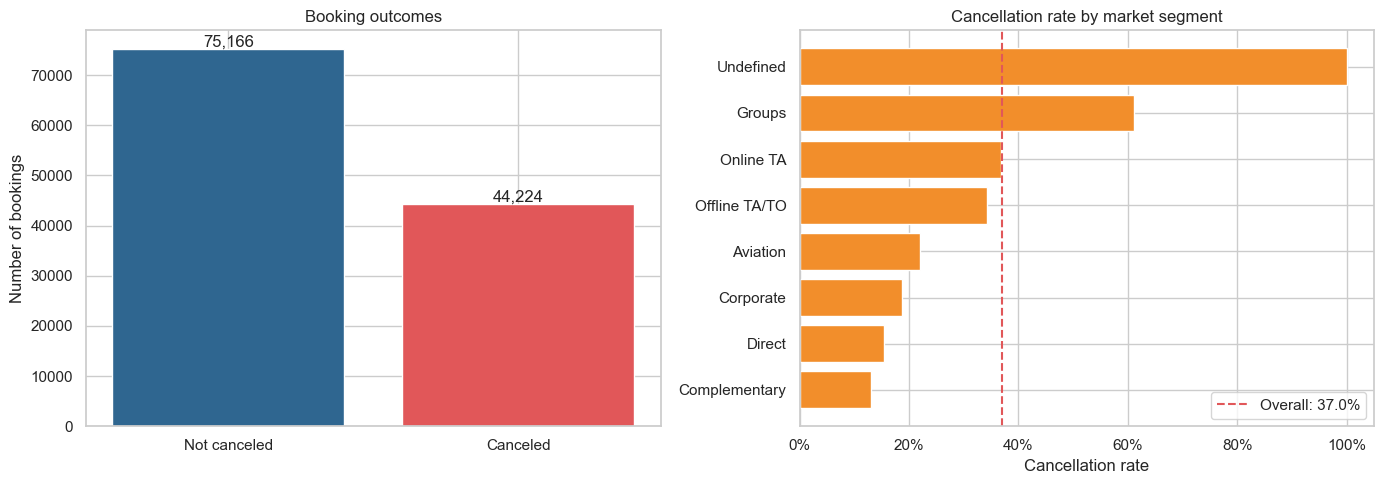

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

status_counts = df["is_canceled"].value_counts().sort_index()
axes[0].bar(
    ["Not canceled", "Canceled"],
    status_counts.values,
    color=[COLORS["primary"], COLORS["danger"]],
)
axes[0].set_title("Booking outcomes")
axes[0].set_ylabel("Number of bookings")
for position, value in enumerate(status_counts.values):
    axes[0].text(position, value, f"{value:,}", ha="center", va="bottom")

segment_plot = segment_summary.sort_values("Cancellation_Rate")
axes[1].barh(
    segment_plot.index.astype(str),
    segment_plot["Cancellation_Rate"],
    color=COLORS["secondary"],
)
axes[1].axvline(
    overall_cancellation_rate,
    color=COLORS["danger"],
    linestyle="--",
    label=f"Overall: {overall_cancellation_rate:.1%}",
)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_title("Cancellation rate by market segment")
axes[1].set_xlabel("Cancellation rate")
axes[1].legend()

plt.tight_layout()
plt.show()


### 2.1 03のSHAP結果

03でValidation 600件を説明したときの、元特徴量単位の上位10件を引用する。ここではSHAPを再計算しない。


,Feature,Aggregated_Mean_Abs_SHAP
0,country,0.1473
1,agent,0.0662
2,customer_type,0.0604
3,market_segment,0.0559
4,lead_time,0.0539
5,arrival_date_year,0.0316
6,previous_cancellations,0.0267
7,required_car_parking_spaces,0.0222
8,distribution_channel,0.0175
9,hotel,0.0156


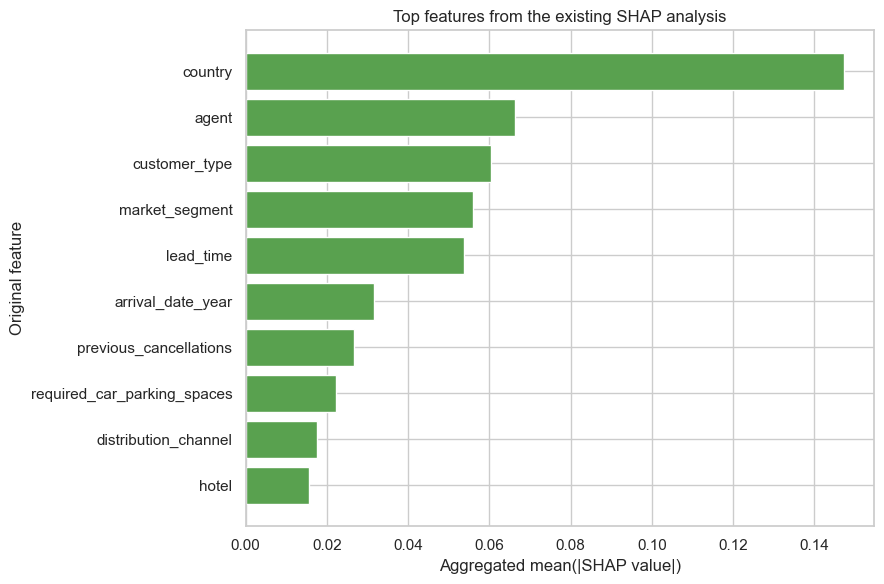

In [4]:
# 既存SHAP NotebookのValidation 600件で得られた、元特徴量単位の上位10件
# 数値はmean(|SHAP|)をOne-Hot展開前の特徴量単位で合計した保存済み結果
shap_top10 = pd.DataFrame({
    "Feature": [
        "country", "agent", "customer_type", "market_segment", "lead_time",
        "arrival_date_year", "previous_cancellations",
        "required_car_parking_spaces", "distribution_channel", "hotel",
    ],
    "Aggregated_Mean_Abs_SHAP": [
        0.147287, 0.066191, 0.060387, 0.055912, 0.053869,
        0.031646, 0.026653, 0.022186, 0.017488, 0.015620,
    ],
})

display(shap_top10)

plot_data = shap_top10.sort_values("Aggregated_Mean_Abs_SHAP")
plt.figure(figsize=(9, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["Aggregated_Mean_Abs_SHAP"],
    color=COLORS["accent"],
)
plt.xlabel("Aggregated mean(|SHAP value|)")
plt.ylabel("Original feature")
plt.title("Top features from the existing SHAP analysis")
plt.tight_layout()
plt.show()


### 2.2 02の最終モデルを再現

02と同じ推定予約日による時系列分割、特徴量除外、前処理Pipelineを使用する。モデルと閾値はValidationで確定済みであり、Final Testの結果を見て変更しない。


In [5]:
arrival_month_number = pd.to_datetime(
    df["arrival_date_month"], format="%B"
).dt.month
arrival_date = pd.to_datetime({
    "year": df["arrival_date_year"],
    "month": arrival_month_number,
    "day": df["arrival_date_day_of_month"],
})
estimated_booking_date = arrival_date - pd.to_timedelta(df["lead_time"], unit="D")

train_cutoff = estimated_booking_date.quantile(0.60, interpolation="lower")
validation_cutoff = estimated_booking_date.quantile(0.80, interpolation="lower")

train_index = df.index[estimated_booking_date <= train_cutoff]
validation_index = df.index[
    (estimated_booking_date > train_cutoff)
    & (estimated_booking_date <= validation_cutoff)
]
final_test_index = df.index[estimated_booking_date > validation_cutoff]

duplicate_group_columns = [
    column
    for column in df.columns
    if column not in [TARGET, "reservation_status", "reservation_status_date"]
]
duplicate_group_id = pd.util.hash_pandas_object(
    df[duplicate_group_columns], index=False
)
train_groups = set(duplicate_group_id.loc[train_index])
validation_groups = set(duplicate_group_id.loc[validation_index])
final_test_groups = set(duplicate_group_id.loc[final_test_index])

assert train_groups.isdisjoint(validation_groups)
assert train_groups.isdisjoint(final_test_groups)
assert validation_groups.isdisjoint(final_test_groups)

split_summary = pd.DataFrame({
    "Rows": [len(train_index), len(validation_index), len(final_test_index)],
    "Start": [
        estimated_booking_date.loc[train_index].min(),
        estimated_booking_date.loc[validation_index].min(),
        estimated_booking_date.loc[final_test_index].min(),
    ],
    "End": [
        estimated_booking_date.loc[train_index].max(),
        estimated_booking_date.loc[validation_index].max(),
        estimated_booking_date.loc[final_test_index].max(),
    ],
    # Final Testの目的変数分布はモデル・閾値確定前に見ない
    "Cancellation_Rate": [
        df.loc[train_index, TARGET].mean(),
        df.loc[validation_index, TARGET].mean(),
        np.nan,
    ],
}, index=["Train", "Validation", "Final Test"])

display(split_summary.style.format({"Cancellation_Rate": "{:.1%}"}))
print("完全重複行数:", int(df.duplicated().sum()))
print("重複グループの分割またぎ: 0")


,Rows,Start,End,Cancellation_Rate
Train,71688,2013-06-24 00:00:00,2016-08-17 00:00:00,38.8%
Validation,23999,2016-08-18 00:00:00,2017-01-12 00:00:00,37.3%
Final Test,23703,2017-01-13 00:00:00,2017-08-31 00:00:00,nan%


完全重複行数: 31994
重複グループの分割またぎ: 0


In [6]:
TARGET = "is_canceled"
COUNTRY = "country"

# 予約登録直後に利用できない、または利用可能性が確認できなかった列を除外する
POST_BOOKING_COLUMNS = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
]
UNCERTAIN_AT_REGISTRATION_COLUMNS = [
    "deposit_type",
    "adr",
    "total_of_special_requests",
]
NOT_USED_COLUMNS = ["agent", "company"]

excluded_columns = set(
    [TARGET, COUNTRY]
    + POST_BOOKING_COLUMNS
    + UNCERTAIN_AT_REGISTRATION_COLUMNS
    + NOT_USED_COLUMNS
)
baseline_feature_columns = [
    column for column in df.columns if column not in excluded_columns
]
country_feature_columns = baseline_feature_columns + [COUNTRY]
agent_feature_columns = country_feature_columns + ["agent"]

# 数値・カテゴリ列はTrainの型情報だけから確定する
train_baseline_data = df.loc[train_index, baseline_feature_columns]
numeric_columns = train_baseline_data.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = train_baseline_data.select_dtypes(exclude=["number"]).columns.tolist()

print("最終モデルのraw特徴量数:", len(agent_feature_columns))
print("除外した予約後・利用時点不明の特徴量:", POST_BOOKING_COLUMNS + UNCERTAIN_AT_REGISTRATION_COLUMNS)


最終モデルのraw特徴量数: 22
除外した予約後・利用時点不明の特徴量: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list', 'deposit_type', 'adr', 'total_of_special_requests']


In [7]:
class TopCountryGrouper(BaseEstimator, TransformerMixin):
    """fitしたデータの上位Nか国を残し、それ以外をOtherへまとめる。"""

    def __init__(self, top_n=17):
        self.top_n = top_n

    @staticmethod
    def _to_series(X):
        if isinstance(X, pd.DataFrame):
            values = X.iloc[:, 0].copy()
        else:
            values = pd.Series(np.asarray(X).reshape(-1))
        return values.fillna("Unknown").astype(str)

    def fit(self, X, y=None):
        values = self._to_series(X)
        self.top_countries_ = (
            values[values != "Unknown"]
            .value_counts()
            .head(self.top_n)
            .index
            .tolist()
        )
        return self

    def transform(self, X):
        check_is_fitted(self, "top_countries_")
        values = self._to_series(X)
        grouped = values.where(
            values.isin(self.top_countries_) | values.eq("Unknown"),
            "Other",
        )
        return grouped.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["country"], dtype=object)


class TopAgentGrouper(BaseEstimator, TransformerMixin):
    """fitしたデータの上位N代理店を残し、それ以外をOtherへまとめる。"""

    def __init__(self, top_n=10):
        self.top_n = top_n

    @staticmethod
    def _normalize_value(value):
        if pd.isna(value):
            return "Unknown"

        # 9.0と9を同じカテゴリ"9"として扱う
        if isinstance(value, (int, float, np.integer, np.floating)):
            numeric_value = float(value)
            if np.isfinite(numeric_value) and numeric_value.is_integer():
                return str(int(numeric_value))
            return format(numeric_value, "g")

        return str(value).strip()

    @classmethod
    def _to_series(cls, X):
        if isinstance(X, pd.DataFrame):
            values = X.iloc[:, 0].copy()
        else:
            values = pd.Series(np.asarray(X).reshape(-1))
        return values.map(cls._normalize_value)

    def fit(self, X, y=None):
        values = self._to_series(X)
        self.top_agents_ = (
            values[values != "Unknown"]
            .value_counts()
            .head(self.top_n)
            .index
            .tolist()
        )
        return self

    def transform(self, X):
        check_is_fitted(self, "top_agents_")
        values = self._to_series(X)
        grouped = values.where(
            values.isin(self.top_agents_) | values.eq("Unknown"),
            "Other",
        )
        return grouped.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["agent"], dtype=object)


In [8]:
# 数値・カテゴリ列はTrainの型情報だけから確定する
train_baseline_data = df.loc[train_index, baseline_feature_columns]
numeric_columns = train_baseline_data.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = train_baseline_data.select_dtypes(exclude=["number"]).columns.tolist()


def build_random_forest_pipeline(
    include_country,
    agent_top_n,
    model_params,
):
    """既存の前処理条件を共通化したRandom Forest Pipelineを作る。"""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    transformers = [
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ]

    if include_country:
        country_pipeline = Pipeline([
            ("group", TopCountryGrouper(top_n=17)),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("country", country_pipeline, [COUNTRY]))

    if agent_top_n is not None:
        agent_pipeline = Pipeline([
            ("group", TopAgentGrouper(top_n=agent_top_n)),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("agent", agent_pipeline, ["agent"]))

    preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(**model_params)),
    ])


def calculate_metrics(y_true, y_pred, y_probability):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability),
        "PR-AUC": average_precision_score(y_true, y_probability),
    }


In [9]:
# 02で確定したモデル設定と判定閾値を使用する
FINAL_RF_PARAMS = {
    "n_estimators": 200,
    "max_depth": 18,
    "min_samples_leaf": 4,
    "min_samples_split": 8,
    "random_state": 42,
    "n_jobs": -1,
}
FINAL_THRESHOLD = 0.30

# 02と同様に、方針確定後はTrainとValidationを結合して最終学習する
development_index = train_index.union(validation_index)
X_development = df.loc[development_index, agent_feature_columns]
y_development = df.loc[development_index, TARGET]
X_final_test = df.loc[final_test_index, agent_feature_columns]
y_final_test = df.loc[final_test_index, TARGET]

final_model = build_random_forest_pipeline(
    include_country=True,
    agent_top_n=10,
    model_params=FINAL_RF_PARAMS,
)
final_model.fit(X_development, y_development)

# 確定済みモデルを再現し、Final Testは性能確認と施策対象の記述だけに使う
final_test_probability = final_model.predict_proba(X_final_test)[:, 1]
final_test_prediction = (final_test_probability >= FINAL_THRESHOLD).astype(int)
final_metrics = calculate_metrics(
    y_final_test,
    final_test_prediction,
    final_test_probability,
)

# 確定済み閾値で施策対象を抽出する（Final Testで閾値は選び直さない）
high_risk_mask = final_test_probability >= FINAL_THRESHOLD
high_risk_count = int(high_risk_mask.sum())
high_risk_cancellations = int(y_final_test.to_numpy()[high_risk_mask].sum())
high_risk_rate = high_risk_cancellations / high_risk_count
high_risk_capture = high_risk_cancellations / int(y_final_test.sum())

final_metrics_table = pd.DataFrame(
    [final_metrics],
    index=[f"Final Test @ {FINAL_THRESHOLD:.2f}"],
)
display(final_metrics_table.round(4))

fitted_country_grouper = (
    final_model.named_steps["preprocess"]
    .named_transformers_["country"]
    .named_steps["group"]
)
fitted_agent_grouper = (
    final_model.named_steps["preprocess"]
    .named_transformers_["agent"]
    .named_steps["group"]
)
print("Train+Validationから選定したcountry:", fitted_country_grouper.top_countries_)
print("Train+Validationから選定したagent:", fitted_agent_grouper.top_agents_)
print("Final Testはモデル・閾値の選択に使用していません。")


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Final Test @ 0.30,0.7407,0.5548,0.8935,0.6846,0.8622,0.7362


Train+Validationから選定したcountry: ['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'ITA', 'IRL', 'BEL', 'BRA', 'NLD', 'USA', 'CHE', 'AUT', 'CN', 'SWE', 'POL', 'CHN']
Train+Validationから選定したagent: ['9', '240', '1', '6', '7', '14', '250', '3', '28', '37']
Final Testはモデル・閾値の選択に使用していません。


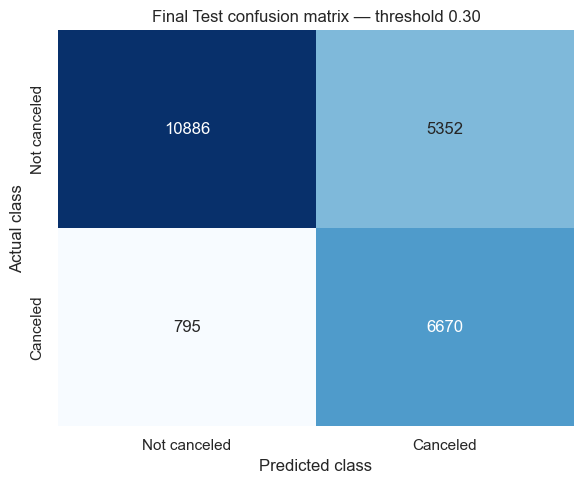

,Predicted_Not_Canceled,Predicted_Canceled
Actual_Not_Canceled,10886,5352
Actual_Canceled,795,6670


In [10]:
final_confusion_matrix = confusion_matrix(
    y_final_test,
    final_test_prediction,
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    final_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not canceled", "Canceled"],
    yticklabels=["Not canceled", "Canceled"],
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(f"Final Test confusion matrix — threshold {FINAL_THRESHOLD:.2f}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = final_confusion_matrix.ravel()
confusion_summary = pd.DataFrame({
    "Predicted_Not_Canceled": [tn, fn],
    "Predicted_Canceled": [fp, tp],
}, index=["Actual_Not_Canceled", "Actual_Canceled"])
display(confusion_summary)


### 2.3 Lead Timeの集計

施策①の根拠として、Lead Timeの分布と区間別キャンセル率を先に整理する。詳細な運用案は第3章で説明する。


In [11]:
lead_time_quantiles = df["lead_time"].quantile([0.25, 0.50, 0.75, 0.90, 0.95])
display(lead_time_quantiles.rename("Lead_Time_Days").to_frame())

lead_time_bins = [-1, 7, 30, 60, 120, 180, 365, np.inf]
lead_time_labels = ["0-7", "8-30", "31-60", "61-120", "121-180", "181-365", "366+"]

lead_time_data = df.assign(
    Lead_Time_Band=pd.cut(
        df["lead_time"],
        bins=lead_time_bins,
        labels=lead_time_labels,
    )
)
lead_time_summary = (
    lead_time_data.groupby("Lead_Time_Band", observed=True)["is_canceled"]
    .agg(Total_Bookings="size", Cancellations="sum", Cancellation_Rate="mean")
)
display(lead_time_summary.style.format({
    "Total_Bookings": "{:,.0f}",
    "Cancellations": "{:,.0f}",
    "Cancellation_Rate": "{:.1%}",
}))

# 61-120日区分から全体平均を上回るため、61日以上を説明可能な施策対象例とする
LEAD_TIME_TARGET_DAYS = 61
lead_time_target_mask = df["lead_time"] >= LEAD_TIME_TARGET_DAYS
lead_time_target_count = int(lead_time_target_mask.sum())
lead_time_target_cancellations = int(
    df.loc[lead_time_target_mask, "is_canceled"].sum()
)
lead_time_target_rate = float(
    df.loc[lead_time_target_mask, "is_canceled"].mean()
)
lead_time_cancel_capture = (
    lead_time_target_cancellations / overall_cancellations
)


,Lead_Time_Days
0.2500,18.0000
0.5000,69.0000
0.7500,160.0000
0.9000,265.0000
0.9500,320.0000


,Total_Bookings,Cancellations,Cancellation_Rate
Lead_Time_Band,,,
0-7,"19,746","1,902",9.6%
8-30,"18,960","5,283",27.9%
31-60,"16,970","6,174",36.4%
61-120,"23,017","9,612",41.8%
121-180,"16,005","7,176",44.8%
181-365,"21,544","11,947",55.5%
366+,"3,148","2,130",67.7%


In [12]:
groups_rate = float(segment_summary.loc["Groups", "Cancellation_Rate"])

display(Markdown(f"""
### 施策検討に使う主な結果

- 全{overall_bookings:,}件のうち{overall_cancellations:,}件がキャンセルで、全体キャンセル率は **{overall_cancellation_rate:.1%}** だった。
- `lead_time`は03のSHAP集約重要度で5位だった。61日以上の予約は **{lead_time_target_count:,}件**、キャンセル率は **{lead_time_target_rate:.1%}** だった。
- `Groups`のキャンセル率は **{groups_rate:.1%}** で、全体平均を上回った。ただし、Groupsという分類がキャンセルの原因だとは断定できない。
- 03のSHAP分析では、元特徴量単位で`country`、`agent`、`customer_type`、`market_segment`、`lead_time`の順に予測寄与が大きかった。
- 最終Random ForestのFinal Test ROC-AUCは **{final_metrics['ROC-AUC']:.4f}**、PR-AUCは **{final_metrics['PR-AUC']:.4f}** だった。
- 02で選定済みの閾値 **{FINAL_THRESHOLD:.2f}** では **{high_risk_count:,}件**が高リスク対象となり、対象内キャンセル率は **{high_risk_rate:.1%}**、全キャンセル捕捉率は **{high_risk_capture:.1%}** だった。

SHAP値とセグメント別キャンセル率は関連や予測への寄与を示すものであり、因果関係を証明するものではない。施策では、顧客属性そのものではなく、連絡時期や確認方法など運用可能な部分を改善する。
"""))



### 施策検討に使う主な結果

- 全119,390件のうち44,224件がキャンセルで、全体キャンセル率は **37.0%** だった。
- `lead_time`は03のSHAP集約重要度で5位だった。61日以上の予約は **63,714件**、キャンセル率は **48.4%** だった。
- `Groups`のキャンセル率は **61.1%** で、全体平均を上回った。ただし、Groupsという分類がキャンセルの原因だとは断定できない。
- 03のSHAP分析では、元特徴量単位で`country`、`agent`、`customer_type`、`market_segment`、`lead_time`の順に予測寄与が大きかった。
- 最終Random ForestのFinal Test ROC-AUCは **0.8622**、PR-AUCは **0.7362** だった。
- 02で選定済みの閾値 **0.30** では **12,022件**が高リスク対象となり、対象内キャンセル率は **55.5%**、全キャンセル捕捉率は **89.4%** だった。

SHAP値とセグメント別キャンセル率は関連や予測への寄与を示すものであり、因果関係を証明するものではない。施策では、顧客属性そのものではなく、連絡時期や確認方法など運用可能な部分を改善する。


# 3. 施策① 早期予約者へのフォロー

予約から宿泊までの期間が長い予約に対し、確認メールやリマインドを送る。まず分布と区間別キャンセル率を確認し、元05と同じく`lead_time >= 61日`を施策対象例とする。


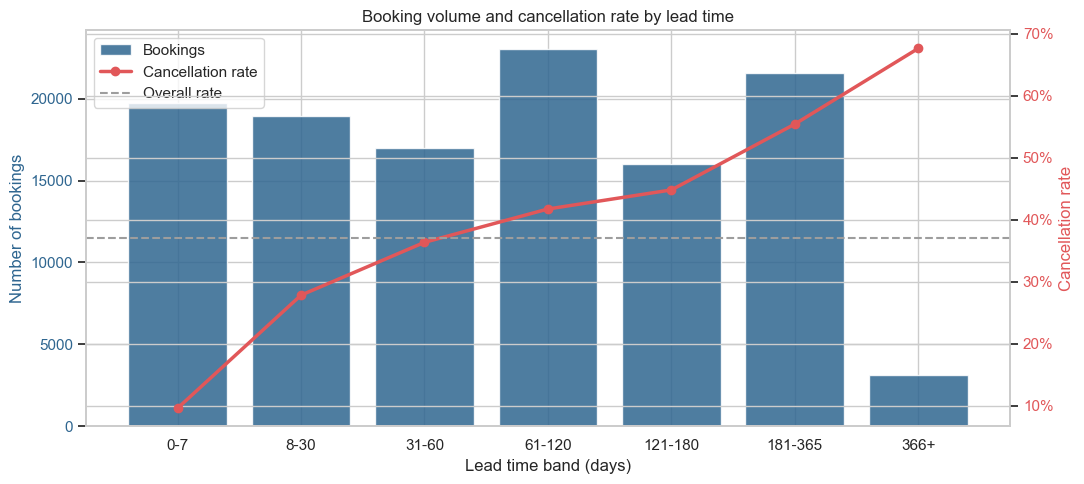

In [13]:
fig, ax1 = plt.subplots(figsize=(11, 5))
x_positions = np.arange(len(lead_time_summary))

bars = ax1.bar(
    x_positions,
    lead_time_summary["Total_Bookings"],
    color=COLORS["primary"],
    alpha=0.85,
    label="Bookings",
)
ax1.set_xlabel("Lead time band (days)")
ax1.set_ylabel("Number of bookings", color=COLORS["primary"])
ax1.set_xticks(x_positions)
ax1.set_xticklabels(lead_time_summary.index.astype(str))
ax1.tick_params(axis="y", labelcolor=COLORS["primary"])

ax2 = ax1.twinx()
ax2.plot(
    x_positions,
    lead_time_summary["Cancellation_Rate"],
    color=COLORS["danger"],
    marker="o",
    linewidth=2.5,
    label="Cancellation rate",
)
ax2.axhline(
    overall_cancellation_rate,
    color=COLORS["neutral"],
    linestyle="--",
    label="Overall rate",
)
ax2.set_ylabel("Cancellation rate", color=COLORS["danger"])
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.tick_params(axis="y", labelcolor=COLORS["danger"])

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
plt.title("Booking volume and cancellation rate by lead time")
fig.tight_layout()
plt.show()


In [14]:
display(Markdown(f"""
### 施策対象と運用案

- **対象例**：リードタイム{LEAD_TIME_TARGET_DAYS}日以上の予約
- **過去データ上の対象件数**：{lead_time_target_count:,}件（全予約の{lead_time_target_count / overall_bookings:.1%}）
- **対象者の実際のキャンセル件数**：{lead_time_target_cancellations:,}件
- **対象者の実際のキャンセル率**：{lead_time_target_rate:.1%}
- **全キャンセルの捕捉割合**：{lead_time_cancel_capture:.1%}

61日以上を対象例としたのは、区間別集計で`61-120日`からキャンセル率が全体平均を上回ったためである。ただし、これは因果効果や最適な境界を証明するものではない。

**実施方法**

1. 予約直後に予約内容と変更方法を分かりやすく案内する。
2. 宿泊30日前と7日前を目安に、自動メールで予定変更の有無を確認する。
3. さらに長い予約では、過剰な連絡にならない範囲で確認時期を追加する。
4. 変更希望を早く把握できる導線を用意し、再販売できる時間を確保する。

**注意点**：対象範囲が広いため、手作業ではなく自動配信を前提とする。メール頻度、配信停止、誤送信、予約変更による顧客体験への影響を確認する必要がある。
"""))



### 施策対象と運用案

- **対象例**：リードタイム61日以上の予約
- **過去データ上の対象件数**：63,714件（全予約の53.4%）
- **対象者の実際のキャンセル件数**：30,865件
- **対象者の実際のキャンセル率**：48.4%
- **全キャンセルの捕捉割合**：69.8%

61日以上を対象例としたのは、区間別集計で`61-120日`からキャンセル率が全体平均を上回ったためである。ただし、これは因果効果や最適な境界を証明するものではない。

**実施方法**

1. 予約直後に予約内容と変更方法を分かりやすく案内する。
2. 宿泊30日前と7日前を目安に、自動メールで予定変更の有無を確認する。
3. さらに長い予約では、過剰な連絡にならない範囲で確認時期を追加する。
4. 変更希望を早く把握できる導線を用意し、再販売できる時間を確保する。

**注意点**：対象範囲が広いため、手作業ではなく自動配信を前提とする。メール頻度、配信停止、誤送信、予約変更による顧客体験への影響を確認する必要がある。


# 4. 施策② Groups予約への対応

`market_segment = Groups`の予約に対し、宿泊前の人数、部屋数、日程、支払条件、キャンセル期限を確認する。

`Groups`は市場セグメント名であり、実際の宿泊人数や団体規模を直接示すとは限らない。キャンセル率が高いという結果と、その原因が判明したことを混同しないようにする。


,Total_Bookings,Cancellations,Cancellation_Rate
market_segment,,,
Undefined,2,2,100.0%
Groups,"19,811","12,097",61.1%
Online TA,"56,477","20,739",36.7%
Offline TA/TO,"24,219","8,311",34.3%
Aviation,237,52,21.9%
Corporate,"5,295",992,18.7%
Direct,"12,606","1,934",15.3%
Complementary,743,97,13.1%


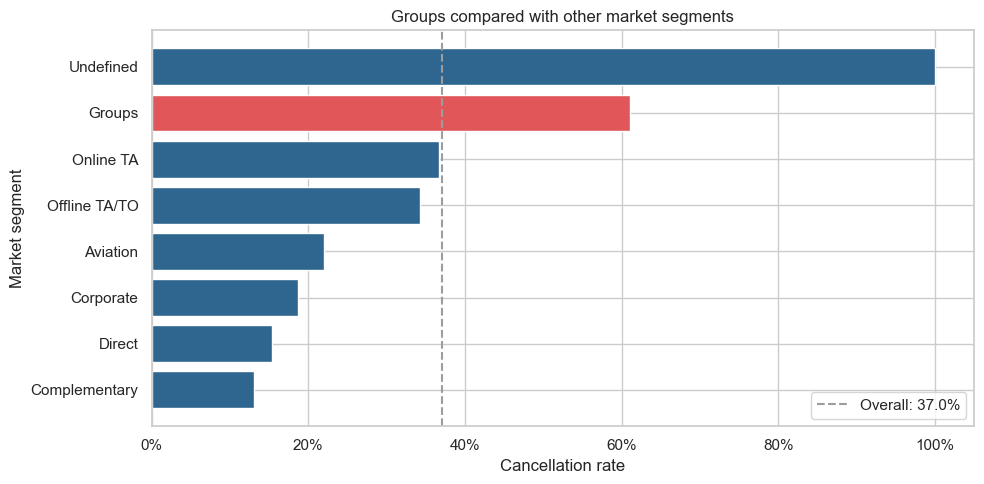

In [15]:
groups_bookings = int(segment_summary.loc["Groups", "Total_Bookings"])
groups_cancellations = int(segment_summary.loc["Groups", "Cancellations"])
groups_cancellation_rate = float(segment_summary.loc["Groups", "Cancellation_Rate"])

display(segment_summary.sort_values("Cancellation_Rate", ascending=False).style.format({
    "Total_Bookings": "{:,.0f}",
    "Cancellations": "{:,.0f}",
    "Cancellation_Rate": "{:.1%}",
}))

segment_plot = segment_summary.sort_values("Cancellation_Rate")
plt.figure(figsize=(10, 5))
bar_colors = [
    COLORS["danger"] if segment == "Groups" else COLORS["primary"]
    for segment in segment_plot.index
]
plt.barh(segment_plot.index.astype(str), segment_plot["Cancellation_Rate"], color=bar_colors)
plt.axvline(
    overall_cancellation_rate,
    color=COLORS["neutral"],
    linestyle="--",
    label=f"Overall: {overall_cancellation_rate:.1%}",
)
plt.gca().xaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Cancellation rate")
plt.ylabel("Market segment")
plt.title("Groups compared with other market segments")
plt.legend()
plt.tight_layout()
plt.show()


In [16]:
display(Markdown(f"""
### 施策対象と運用案

- **Groups予約件数**：{groups_bookings:,}件
- **Groupsのキャンセル件数**：{groups_cancellations:,}件
- **Groupsのキャンセル率**：{groups_cancellation_rate:.1%}
- **全体キャンセル率との差**：{groups_cancellation_rate - overall_cancellation_rate:+.1%}ポイント

**具体的な運用**

1. 予約後に代表者、人数、部屋数、日程、支払条件、変更期限を確認する。
2. 宿泊45日前・14日前など、施設の変更期限に合わせて段階的に再確認する。
3. 人数未確定の場合は仮確保と確定期限を区別し、早い段階で在庫を解放できる運用にする。
4. 変更履歴や担当者との連絡記録を残し、次回の運用改善に利用する。

Groupsはキャンセル率が高く、対象の定義も比較的明確である。一方、データだけでは実際の団体規模や契約条件が分からないため、施策導入前に業務上の定義と照合する必要がある。
"""))



### 施策対象と運用案

- **Groups予約件数**：19,811件
- **Groupsのキャンセル件数**：12,097件
- **Groupsのキャンセル率**：61.1%
- **全体キャンセル率との差**：+24.0%ポイント

**具体的な運用**

1. 予約後に代表者、人数、部屋数、日程、支払条件、変更期限を確認する。
2. 宿泊45日前・14日前など、施設の変更期限に合わせて段階的に再確認する。
3. 人数未確定の場合は仮確保と確定期限を区別し、早い段階で在庫を解放できる運用にする。
4. 変更履歴や担当者との連絡記録を残し、次回の運用改善に利用する。

Groupsはキャンセル率が高く、対象の定義も比較的明確である。一方、データだけでは実際の団体規模や契約条件が分からないため、施策導入前に業務上の定義と照合する必要がある。


# 5. 施策③ 機械学習による高リスク予約への対応

02で採用したRandom Forestと閾値0.30を変更せず、Final Testで高リスクと判定された予約を施策対象として記述する。Final Testはモデルや閾値の再選択には使用しない。


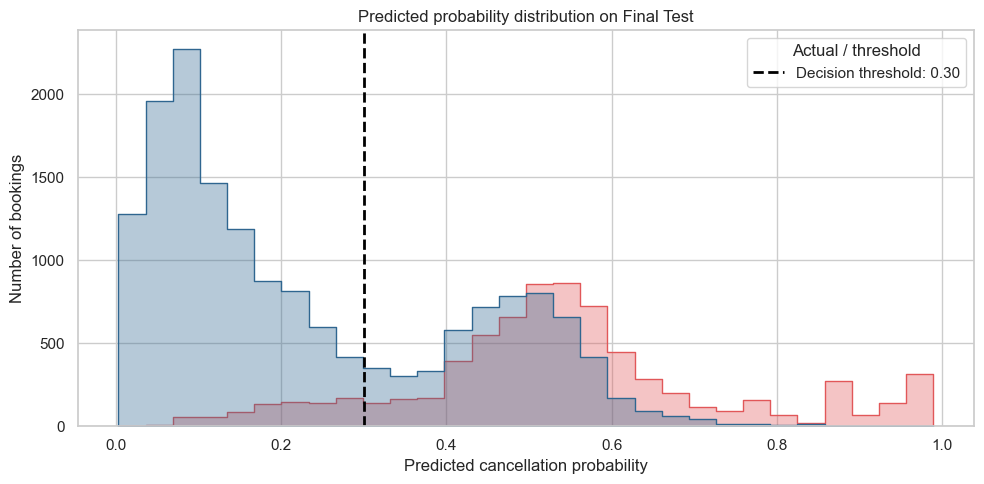

,Target_Rule,Target_Bookings,Target_Share,Actual_Cancellations_in_Target,Actual_Cancellation_Rate_Precision,Cancellation_Capture_Recall
0,Probability >= 0.30,"12,022",50.7%,"6,670",55.5%,89.4%


In [17]:
# Final Testの予測確率分布と、02で確定した閾値0.30を確認する
final_test_analysis = df.loc[
    final_test_index,
    ["lead_time", "market_segment", "customer_type", "previous_cancellations"],
].copy()
final_test_analysis["Actual_Canceled"] = y_final_test.to_numpy()
final_test_analysis["Cancellation_Probability"] = final_test_probability
final_test_analysis["Predicted_Canceled"] = final_test_prediction

plt.figure(figsize=(10, 5))
sns.histplot(
    data=final_test_analysis,
    x="Cancellation_Probability",
    hue="Actual_Canceled",
    bins=30,
    stat="count",
    common_norm=False,
    element="step",
    palette={0: COLORS["primary"], 1: COLORS["danger"]},
    alpha=0.35,
)
plt.axvline(
    FINAL_THRESHOLD,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Decision threshold: {FINAL_THRESHOLD:.2f}",
)
plt.xlabel("Predicted cancellation probability")
plt.ylabel("Number of bookings")
plt.title("Predicted probability distribution on Final Test")
plt.legend(title="Actual / threshold")
plt.tight_layout()
plt.show()

threshold_target_summary = pd.DataFrame({
    "Target_Rule": [f"Probability >= {FINAL_THRESHOLD:.2f}"],
    "Target_Bookings": [high_risk_count],
    "Target_Share": [high_risk_count / len(y_final_test)],
    "Actual_Cancellations_in_Target": [high_risk_cancellations],
    "Actual_Cancellation_Rate_Precision": [high_risk_rate],
    "Cancellation_Capture_Recall": [high_risk_capture],
})
display(threshold_target_summary.style.format({
    "Target_Bookings": "{:,.0f}",
    "Target_Share": "{:.1%}",
    "Actual_Cancellations_in_Target": "{:,.0f}",
    "Actual_Cancellation_Rate_Precision": "{:.1%}",
    "Cancellation_Capture_Recall": "{:.1%}",
}))


### 5.1 高リスク群の特徴

施策内容を考えるため、確定済み閾値で抽出した高リスク群とFinal Test全体を比較する。これは対象群の記述であり、新しい特徴量選択やモデル調整ではない。


In [18]:
# 高リスク群の特徴をFinal Test全体と比較する
high_risk_rows = final_test_analysis.loc[high_risk_mask]

high_risk_profile = pd.DataFrame({
    "Final_Test_All": [
        final_test_analysis["lead_time"].mean(),
        (final_test_analysis["lead_time"] >= LEAD_TIME_TARGET_DAYS).mean(),
        final_test_analysis["market_segment"].eq("Groups").mean(),
        final_test_analysis["customer_type"].eq("Transient").mean(),
        final_test_analysis["previous_cancellations"].gt(0).mean(),
    ],
    "High_Risk_Threshold_0.30": [
        high_risk_rows["lead_time"].mean(),
        (high_risk_rows["lead_time"] >= LEAD_TIME_TARGET_DAYS).mean(),
        high_risk_rows["market_segment"].eq("Groups").mean(),
        high_risk_rows["customer_type"].eq("Transient").mean(),
        high_risk_rows["previous_cancellations"].gt(0).mean(),
    ],
}, index=[
    "Average lead_time (days)",
    f"Share: lead_time >= {LEAD_TIME_TARGET_DAYS}",
    "Share: market_segment = Groups",
    "Share: customer_type = Transient",
    "Share: previous_cancellations > 0",
])

display(high_risk_profile.style.format({
    "Final_Test_All": "{:.1%}",
    "High_Risk_Threshold_0.30": "{:.1%}",
}, subset=pd.IndexSlice[high_risk_profile.index[1:], :]).format(
    "{:.1f}", subset=pd.IndexSlice[["Average lead_time (days)"], :]
))


,Final_Test_All,High_Risk_Threshold_0.30
Average lead_time (days),57.5,74.9
Share: lead_time >= 61,38.0%,50.2%
Share: market_segment = Groups,6.2%,8.8%
Share: customer_type = Transient,87.9%,94.6%
Share: previous_cancellations > 0,1.0%,0.3%


### 5.2 対応可能件数による比較

スタッフが対応できる件数に上限がある場合を想定し、予測確率上位10%・20%・30%も併記する。これは運用量の比較であり、最終閾値を選び直すための分析ではない。


In [19]:
# 対応可能件数を先に決める運用を想定し、予測確率上位10%・20%・30%を比較する
sorted_positions = np.argsort(-final_test_probability, kind="mergesort")
total_final_cancellations = int(y_final_test.sum())
capacity_rows = []

for target_share in [0.10, 0.20, 0.30]:
    target_count = int(np.ceil(len(y_final_test) * target_share))
    selected_positions = sorted_positions[:target_count]
    selected_actual = y_final_test.to_numpy()[selected_positions]
    captured_cancellations = int(selected_actual.sum())
    probability_cutoff = float(final_test_probability[selected_positions].min())

    capacity_rows.append({
        "Target_Group": f"Top {int(target_share * 100)}%",
        "Target_Bookings": target_count,
        "Target_Share": target_count / len(y_final_test),
        "Probability_Cutoff": probability_cutoff,
        "Actual_Cancellations_in_Target": captured_cancellations,
        "Precision_Target_Cancel_Rate": captured_cancellations / target_count,
        "Recall_Cancellation_Capture": captured_cancellations / total_final_cancellations,
        "Lift_vs_Final_Test": (
            captured_cancellations / target_count
        ) / float(y_final_test.mean()),
    })

capacity_comparison = pd.DataFrame(capacity_rows).set_index("Target_Group")
display(capacity_comparison.style.format({
    "Target_Bookings": "{:,.0f}",
    "Target_Share": "{:.1%}",
    "Probability_Cutoff": "{:.3f}",
    "Actual_Cancellations_in_Target": "{:,.0f}",
    "Precision_Target_Cancel_Rate": "{:.1%}",
    "Recall_Cancellation_Capture": "{:.1%}",
    "Lift_vs_Final_Test": "{:.2f}x",
}))


,Target_Bookings,Target_Share,Probability_Cutoff,Actual_Cancellations_in_Target,Precision_Target_Cancel_Rate,Recall_Cancellation_Capture,Lift_vs_Final_Test
Target_Group,,,,,,,
Top 10%,"2,371",10.0%,0.607,"2,012",84.9%,27.0%,2.69x
Top 20%,"4,741",20.0%,0.539,"3,446",72.7%,46.2%,2.31x
Top 30%,"7,111",30.0%,0.492,"4,685",65.9%,62.8%,2.09x


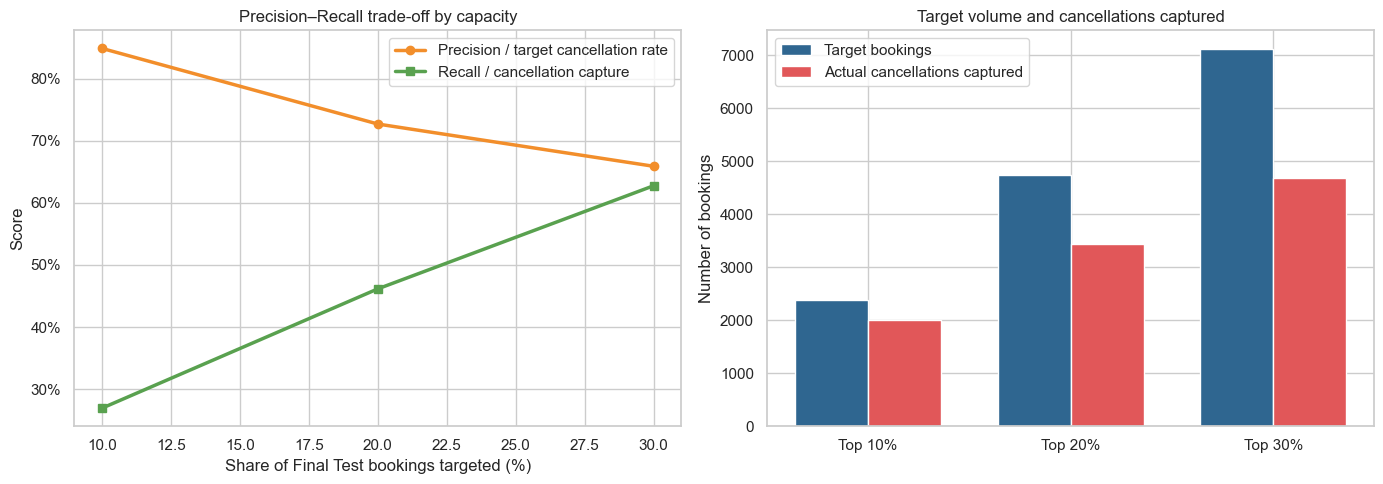

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

shares_percent = capacity_comparison["Target_Share"] * 100
axes[0].plot(
    shares_percent,
    capacity_comparison["Precision_Target_Cancel_Rate"],
    marker="o",
    linewidth=2.5,
    label="Precision / target cancellation rate",
    color=COLORS["secondary"],
)
axes[0].plot(
    shares_percent,
    capacity_comparison["Recall_Cancellation_Capture"],
    marker="s",
    linewidth=2.5,
    label="Recall / cancellation capture",
    color=COLORS["accent"],
)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_xlabel("Share of Final Test bookings targeted (%)")
axes[0].set_ylabel("Score")
axes[0].set_title("Precision–Recall trade-off by capacity")
axes[0].legend()

x = np.arange(len(capacity_comparison))
width = 0.36
axes[1].bar(
    x - width / 2,
    capacity_comparison["Target_Bookings"],
    width,
    label="Target bookings",
    color=COLORS["primary"],
)
axes[1].bar(
    x + width / 2,
    capacity_comparison["Actual_Cancellations_in_Target"],
    width,
    label="Actual cancellations captured",
    color=COLORS["danger"],
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(capacity_comparison.index)
axes[1].set_ylabel("Number of bookings")
axes[1].set_title("Target volume and cancellations captured")
axes[1].legend()

plt.tight_layout()
plt.show()


In [21]:
top10_result = capacity_comparison.loc["Top 10%"]
top20_result = capacity_comparison.loc["Top 20%"]
top30_result = capacity_comparison.loc["Top 30%"]

display(Markdown(f"""
### 高リスク予約の分析結果

- 閾値{FINAL_THRESHOLD:.2f}での対象件数：**{high_risk_count:,}件**（Final Testの{high_risk_count / len(y_final_test):.1%}）
- 対象内の実キャンセル：**{high_risk_cancellations:,}件**
- 対象者の実キャンセル率（Precision）：**{high_risk_rate:.1%}**
- 全キャンセルの捕捉割合（Recall）：**{high_risk_capture:.1%}**
- 上位10%：対象{int(top10_result['Target_Bookings']):,}件、Precision {top10_result['Precision_Target_Cancel_Rate']:.1%}、Recall {top10_result['Recall_Cancellation_Capture']:.1%}
- 上位20%：対象{int(top20_result['Target_Bookings']):,}件、Precision {top20_result['Precision_Target_Cancel_Rate']:.1%}、Recall {top20_result['Recall_Cancellation_Capture']:.1%}
- 上位30%：対象{int(top30_result['Target_Bookings']):,}件、Precision {top30_result['Precision_Target_Cancel_Rate']:.1%}、Recall {top30_result['Recall_Cancellation_Capture']:.1%}

閾値0.30ではキャンセルの見逃しを減らせる一方、Final Testの約半数が対象となる。そこで、対象全体には自動メールなど低コストの対応を行い、電話など負荷の高い対応は予測確率順や`Groups`該当の有無で優先順位を付ける方法が現実的である。

03のSHAP分析では`lead_time`や`market_segment`も重要だった。高リスク予約のうち長期予約には施策①、`Groups`には施策②の内容を使う。ただし、`country`や`agent`だけを理由に不利益な対応を行わず、公平性を確認する。
"""))



### 高リスク予約の分析結果

- 閾値0.30での対象件数：**12,022件**（Final Testの50.7%）
- 対象内の実キャンセル：**6,670件**
- 対象者の実キャンセル率（Precision）：**55.5%**
- 全キャンセルの捕捉割合（Recall）：**89.4%**
- 上位10%：対象2,371件、Precision 84.9%、Recall 27.0%
- 上位20%：対象4,741件、Precision 72.7%、Recall 46.2%
- 上位30%：対象7,111件、Precision 65.9%、Recall 62.8%

閾値0.30ではキャンセルの見逃しを減らせる一方、Final Testの約半数が対象となる。そこで、対象全体には自動メールなど低コストの対応を行い、電話など負荷の高い対応は予測確率順や`Groups`該当の有無で優先順位を付ける方法が現実的である。

03のSHAP分析では`lead_time`や`market_segment`も重要だった。高リスク予約のうち長期予約には施策①、`Groups`には施策②の内容を使う。ただし、`country`や`agent`だけを理由に不利益な対応を行わず、公平性を確認する。


# 6. 費用対効果シミュレーション

閾値0.30の高リスク予約を対象に、元05と同じ仮定で感度分析を行う。

- 施策1件あたりのコスト：300円（仮定）
- キャンセル防止1件あたりの追加利益：12,000円（仮定）
- キャンセル削減率：5%・10%・15%（仮定）

計算式は、`総コスト = 対象件数 × 1件あたりコスト`、`防止件数 = 対象内の実キャンセル件数 × 削減率`、`差引利益 = 防止件数 × 追加利益 − 総コスト`とする。


In [22]:
# 変更可能な仮定値
ACTION_COST_PER_BOOKING_YEN = 300
PROFIT_PER_PREVENTED_CANCELLATION_YEN = 12_000
CANCELLATION_REDUCTION_SCENARIOS = [0.05, 0.10, 0.15]

# 実データから確定する値
simulation_target_bookings = high_risk_count
simulation_target_cancellations = high_risk_cancellations

simulation_inputs = pd.DataFrame([
    {
        "Parameter": "Target bookings",
        "Value": simulation_target_bookings,
        "Source": "Final Test actual/model output",
        "Type": "Actual data",
    },
    {
        "Parameter": "Actual cancellations in target",
        "Value": simulation_target_cancellations,
        "Source": "Final Test actual outcome",
        "Type": "Actual data",
    },
    {
        "Parameter": "Action cost per booking (JPY)",
        "Value": ACTION_COST_PER_BOOKING_YEN,
        "Source": "Illustrative assumption; replace with operational cost",
        "Type": "Assumption",
    },
    {
        "Parameter": "Profit per prevented cancellation (JPY)",
        "Value": PROFIT_PER_PREVENTED_CANCELLATION_YEN,
        "Source": "Illustrative assumption; replace with contribution margin",
        "Type": "Assumption",
    },
])
display(simulation_inputs)

total_action_cost = simulation_target_bookings * ACTION_COST_PER_BOOKING_YEN
simulation_rows = []

for reduction_rate in CANCELLATION_REDUCTION_SCENARIOS:
    prevented_cancellations = simulation_target_cancellations * reduction_rate
    additional_profit = (
        prevented_cancellations * PROFIT_PER_PREVENTED_CANCELLATION_YEN
    )
    net_profit = additional_profit - total_action_cost
    simulation_rows.append({
        "Cancellation_Reduction_Rate": reduction_rate,
        "Total_Action_Cost_Yen": total_action_cost,
        "Expected_Prevented_Cancellations": prevented_cancellations,
        "Expected_Additional_Profit_Yen": additional_profit,
        "Expected_Net_Profit_Yen": net_profit,
    })

roi_simulation = pd.DataFrame(simulation_rows)
display(roi_simulation.style.format({
    "Cancellation_Reduction_Rate": "{:.0%}",
    "Total_Action_Cost_Yen": "¥{:,.0f}",
    "Expected_Prevented_Cancellations": "{:,.1f}",
    "Expected_Additional_Profit_Yen": "¥{:,.0f}",
    "Expected_Net_Profit_Yen": "¥{:,.0f}",
}))

break_even_prevented_exact = (
    total_action_cost / PROFIT_PER_PREVENTED_CANCELLATION_YEN
)
break_even_prevented_integer = int(np.ceil(break_even_prevented_exact))
break_even_reduction_rate = (
    break_even_prevented_exact / simulation_target_cancellations
)

break_even_summary = pd.DataFrame({
    "Metric": [
        "Break-even prevented cancellations (exact)",
        "Break-even prevented cancellations (integer)",
        "Break-even cancellation reduction rate",
    ],
    "Value": [
        break_even_prevented_exact,
        break_even_prevented_integer,
        break_even_reduction_rate,
    ],
})
display(break_even_summary)


,Parameter,Value,Source,Type
0,Target bookings,12022,Final Test actual/model output,Actual data
1,Actual cancellations in target,6670,Final Test actual outcome,Actual data
2,Action cost per booking (JPY),300,Illustrative assumption; replace with operatio...,Assumption
3,Profit per prevented cancellation (JPY),12000,Illustrative assumption; replace with contribu...,Assumption


,Cancellation_Reduction_Rate,Total_Action_Cost_Yen,Expected_Prevented_Cancellations,Expected_Additional_Profit_Yen,Expected_Net_Profit_Yen
0,5%,"¥3,606,600",333.5,"¥4,002,000","¥395,400"
1,10%,"¥3,606,600",667.0,"¥8,004,000","¥4,397,400"
2,15%,"¥3,606,600","1,000.5","¥12,006,000","¥8,399,400"


,Metric,Value
0,Break-even prevented cancellations (exact),300.5500
1,Break-even prevented cancellations (integer),301.0000
2,Break-even cancellation reduction rate,0.0451


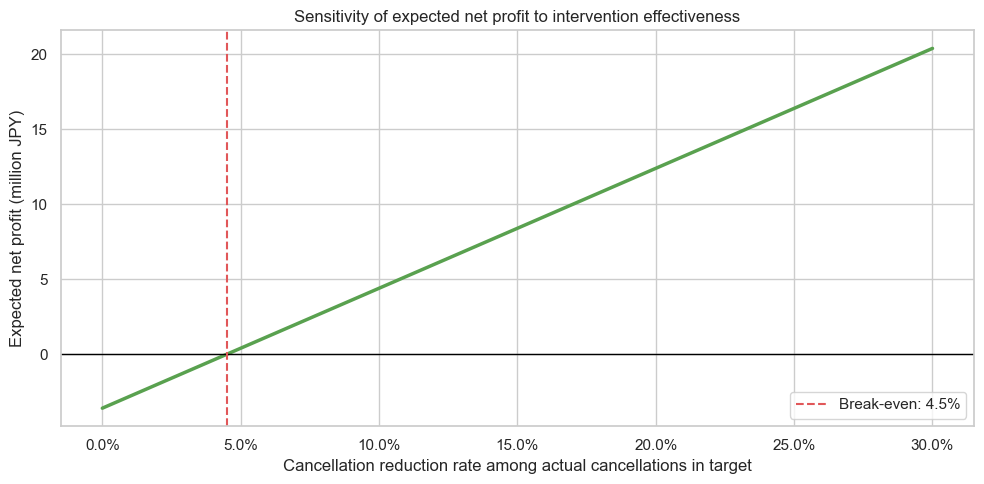

In [23]:
reduction_rate_grid = np.linspace(0, 0.30, 61)
net_profit_grid = (
    simulation_target_cancellations
    * reduction_rate_grid
    * PROFIT_PER_PREVENTED_CANCELLATION_YEN
    - total_action_cost
)

plt.figure(figsize=(10, 5))
plt.plot(
    reduction_rate_grid,
    net_profit_grid / 1_000_000,
    color=COLORS["accent"],
    linewidth=2.5,
)
plt.axhline(0, color="black", linewidth=1)
plt.axvline(
    break_even_reduction_rate,
    color=COLORS["danger"],
    linestyle="--",
    label=f"Break-even: {break_even_reduction_rate:.1%}",
)
plt.gca().xaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Cancellation reduction rate among actual cancellations in target")
plt.ylabel("Expected net profit (million JPY)")
plt.title("Sensitivity of expected net profit to intervention effectiveness")
plt.legend()
plt.tight_layout()
plt.show()


In [24]:
net_profit_5 = float(
    roi_simulation.loc[
        roi_simulation["Cancellation_Reduction_Rate"] == 0.05,
        "Expected_Net_Profit_Yen",
    ].iloc[0]
)
net_profit_10 = float(
    roi_simulation.loc[
        roi_simulation["Cancellation_Reduction_Rate"] == 0.10,
        "Expected_Net_Profit_Yen",
    ].iloc[0]
)
net_profit_15 = float(
    roi_simulation.loc[
        roi_simulation["Cancellation_Reduction_Rate"] == 0.15,
        "Expected_Net_Profit_Yen",
    ].iloc[0]
)

display(Markdown(f"""
### シミュレーションから得られる示唆

- 施策コストの仮定は1件 **¥{ACTION_COST_PER_BOOKING_YEN:,}**、キャンセル防止1件あたりの追加利益は **¥{PROFIT_PER_PREVENTED_CANCELLATION_YEN:,}** とした。
- 対象{simulation_target_bookings:,}件への総コストは **¥{total_action_cost:,.0f}** となる。
- 削減率5%・10%・15%の差引利益は、それぞれ **¥{net_profit_5:,.0f}**、**¥{net_profit_10:,.0f}**、**¥{net_profit_15:,.0f}** と試算された。
- 損益分岐点は約 **{break_even_prevented_exact:,.1f}件**、整数では **{break_even_prevented_integer:,}件** のキャンセル防止で、対象内の実キャンセルに対する削減率では **{break_even_reduction_rate:.1%}** である。

この金額は実績ではなく、仮定を置いた感度分析である。実務では、メール・電話・システム費用、追加業務時間、キャンセル料収入、再販売できる確率、宿泊日数、食事などの追加売上、変動費を使って単価を置き換える必要がある。

ADRは客室単価であり利益ではないため、本試算では直接利用していない。ADRを使う場合でも、`ADR × 宿泊日数`を売上の出発点とし、キャンセル料、再販売可能性、販売手数料、清掃・食事などの変動費を考慮する必要がある。
"""))



### シミュレーションから得られる示唆

- 施策コストの仮定は1件 **¥300**、キャンセル防止1件あたりの追加利益は **¥12,000** とした。
- 対象12,022件への総コストは **¥3,606,600** となる。
- 削減率5%・10%・15%の差引利益は、それぞれ **¥395,400**、**¥4,397,400**、**¥8,399,400** と試算された。
- 損益分岐点は約 **300.6件**、整数では **301件** のキャンセル防止で、対象内の実キャンセルに対する削減率では **4.5%** である。

この金額は実績ではなく、仮定を置いた感度分析である。実務では、メール・電話・システム費用、追加業務時間、キャンセル料収入、再販売できる確率、宿泊日数、食事などの追加売上、変動費を使って単価を置き換える必要がある。

ADRは客室単価であり利益ではないため、本試算では直接利用していない。ADRを使う場合でも、`ADR × 宿泊日数`を売上の出発点とし、キャンセル料、再販売可能性、販売手数料、清掃・食事などの変動費を考慮する必要がある。


# 7. A/Bテストによる効果検証

この分析だけでは、リマインドや再確認によって実際にキャンセルが減るかは分からない。導入時は、確定済みモデルで対象を抽出したうえでA/Bテストを行う。

- **対象**：予測確率0.30以上の新規予約
- **割付**：ホテル種別、予測確率帯、`Groups`の有無などで層別化し、通常対応のControl群と施策を行うTreatment群へ無作為に割り付ける
- **主要指標**：予約単位のキャンセル率
- **副次指標**：予約変更率、再販売までの日数、苦情件数、施策コスト、限界利益
- **評価**：割付時点の群で比較するITT分析を基本とする
- **注意点**：必要サンプル数と終了条件を事前に決め、途中結果を見て都合よく停止しない

A/Bテストは今後の検証案であり、本プロジェクトでは実施していない。


# 8. 最終的な提案と今後の課題

3施策について、対象・根拠・運用負荷を比較する。


In [25]:
recommendation_comparison = pd.DataFrame([
    {
        "施策": "① 早期予約者フォロー",
        "目的": "予定変更・予約忘れの早期把握",
        "対象者": f"lead_time >= {LEAD_TIME_TARGET_DAYS}日",
        "データ範囲": "全期間の記述統計",
        "分析上の根拠": f"{lead_time_target_count:,}件、キャンセル率{lead_time_target_rate:.1%}",
        "実施コスト": "低〜中（自動メール前提）",
        "運用難易度": "低〜中",
        "期待メリット": "広い対象へ低コストで接触可能",
        "リスク・注意点": "対象が広い、連絡過多、因果効果は未検証",
    },
    {
        "施策": "② Groups予約確認",
        "目的": "人数・部屋数・日程の早期確定",
        "対象者": "market_segment = Groups",
        "データ範囲": "全期間の記述統計",
        "分析上の根拠": f"{groups_bookings:,}件、キャンセル率{groups_cancellation_rate:.1%}",
        "実施コスト": "中（個別確認を含む）",
        "運用難易度": "中",
        "期待メリット": "対象定義が明確、在庫解放を早められる可能性",
        "リスク・注意点": "Groupsが実人数・契約規模を直接表さない",
    },
    {
        "施策": "③ モデル高リスク優先対応",
        "目的": "限られた対応能力を高リスク予約へ集中",
        "対象者": f"予測確率 >= {FINAL_THRESHOLD:.2f}",
        "データ範囲": "時系列Final Test",
        "分析上の根拠": (
            f"{high_risk_count:,}件、Precision {high_risk_rate:.1%}、"
            f"Recall {high_risk_capture:.1%}"
        ),
        "実施コスト": "低〜高（対応方法で調整）",
        "運用難易度": "高",
        "期待メリット": "優先順位付けと対応量の管理が可能",
        "リスク・注意点": "誤検知、分布変化、公平性、モデル監視が必要",
    },
])
display(recommendation_comparison)


,施策,目的,対象者,データ範囲,分析上の根拠,実施コスト,運用難易度,期待メリット,リスク・注意点
0,① 早期予約者フォロー,予定変更・予約忘れの早期把握,lead_time >= 61日,全期間の記述統計,"63,714件、キャンセル率48.4%",低〜中（自動メール前提）,低〜中,広い対象へ低コストで接触可能,対象が広い、連絡過多、因果効果は未検証
1,② Groups予約確認,人数・部屋数・日程の早期確定,market_segment = Groups,全期間の記述統計,"19,811件、キャンセル率61.1%",中（個別確認を含む）,中,対象定義が明確、在庫解放を早められる可能性,Groupsが実人数・契約規模を直接表さない
2,③ モデル高リスク優先対応,限られた対応能力を高リスク予約へ集中,予測確率 >= 0.30,時系列Final Test,"12,022件、Precision 55.5%、Recall 89.4%",低〜高（対応方法で調整）,高,優先順位付けと対応量の管理が可能,誤検知、分布変化、公平性、モデル監視が必要


In [26]:
display(Markdown(f"""
## 優先順位の提案

1. **施策③を対象選定の中心にする。** 閾値{FINAL_THRESHOLD:.2f}ではFinal Testの{high_risk_count / len(y_final_test):.1%}が対象となるため、全対象には自動メールなど低コストの対応を行う。
2. **高コストな個別対応は確率順に絞る。** 電話確認などは、予測確率上位層や高リスクかつ`Groups`の予約を優先する。
3. **施策①・②を具体的な対応内容として組み合わせる。** 長期予約には段階的なリマインド、`Groups`には人数・日程・期限の確認を行う。

## 結論

- リードタイム{LEAD_TIME_TARGET_DAYS}日以上は{lead_time_target_count:,}件で、キャンセル率は **{lead_time_target_rate:.1%}** だった。
- `Groups`は{groups_bookings:,}件で、キャンセル率は **{groups_cancellation_rate:.1%}** だった。
- 最終Random ForestはFinal TestでROC-AUC **{final_metrics['ROC-AUC']:.3f}**、PR-AUC **{final_metrics['PR-AUC']:.3f}** だった。
- 閾値{FINAL_THRESHOLD:.2f}では{high_risk_count:,}件を対象とし、対象内キャンセル率は **{high_risk_rate:.1%}**、全キャンセル捕捉率は **{high_risk_capture:.1%}** だった。
- 仮定したコストと追加利益では、損益分岐となるキャンセル削減率は **{break_even_reduction_rate:.1%}** だった。これは実績ではなく、A/Bテストで検証すべき仮定である。

## 今後の課題

- 予約IDがないため、完全一致行が同一予約か、同じ条件の別予約かを判別できない。
- 予約登録日は到着日と`lead_time`から近似しており、実際の予約更新履歴は分からない。
- SHAPやセグメント別キャンセル率は因果効果を示さない。
- 実際の費用、限界利益、キャンセル料、再販売率を使ってシミュレーションを更新する必要がある。
- 将来期間でモデル性能、確率校正、公平性、業務負荷を継続的に確認する必要がある。
"""))



## 優先順位の提案

1. **施策③を対象選定の中心にする。** 閾値0.30ではFinal Testの50.7%が対象となるため、全対象には自動メールなど低コストの対応を行う。
2. **高コストな個別対応は確率順に絞る。** 電話確認などは、予測確率上位層や高リスクかつ`Groups`の予約を優先する。
3. **施策①・②を具体的な対応内容として組み合わせる。** 長期予約には段階的なリマインド、`Groups`には人数・日程・期限の確認を行う。

## 結論

- リードタイム61日以上は63,714件で、キャンセル率は **48.4%** だった。
- `Groups`は19,811件で、キャンセル率は **61.1%** だった。
- 最終Random ForestはFinal TestでROC-AUC **0.862**、PR-AUC **0.736** だった。
- 閾値0.30では12,022件を対象とし、対象内キャンセル率は **55.5%**、全キャンセル捕捉率は **89.4%** だった。
- 仮定したコストと追加利益では、損益分岐となるキャンセル削減率は **4.5%** だった。これは実績ではなく、A/Bテストで検証すべき仮定である。

## 今後の課題

- 予約IDがないため、完全一致行が同一予約か、同じ条件の別予約かを判別できない。
- 予約登録日は到着日と`lead_time`から近似しており、実際の予約更新履歴は分からない。
- SHAPやセグメント別キャンセル率は因果効果を示さない。
- 実際の費用、限界利益、キャンセル料、再販売率を使ってシミュレーションを更新する必要がある。
- 将来期間でモデル性能、確率校正、公平性、業務負荷を継続的に確認する必要がある。
